# 1.4_gridsearch: extreme facular geometries at v_eq = 4000 m/s, chi^2 with a free vertical offset over three strong-line windows

Forward-models polar caps, an equatorial band and bands at +/-30 deg, each tuned to a visible-disk filling factor of 10, 20 and 50% at i = 0, 45 and 90 deg (res3d = 5, res2d = 200), then generates a disk with randomly placed faculae and finds the grid spectrum with the lowest chi^2 against it.

Same runs and caches as 1.3 (spectra are simulated over 430-440 nm), but chi^2 and its offset use only the bins in three line windows: 4368.780-4369.138 A, 4377.159 A and 4380.460 A, each padded by +/-0.3 A.

Photosphere: real SSD (with lines). Facula: 200G. Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import sys
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import actress.contrasts as contrst

Using existing test_phot_ssd_4300_4400_new.txt
Using existing test_fac_200G_4300_4400_new.txt
11473 wavelengths, 4300.0980-4399.8999 A; images at 4384.7640 A (I0_fac / I0_phot = 2.245)



run                          half-width (deg) target ff visible ff  strips (lower, upper) deg
polar_caps_ff0.10_i0                   19.093      0.10     0.0988  (-90.00, -70.91), (70.91, 90.00)
polar_caps_ff0.20_i0                   26.552      0.20     0.1894  (-90.00, -63.45), (63.45, 90.00)
polar_caps_ff0.50_i0                   45.006      0.50     0.4870  (-90.00, -44.99), (44.99, 90.00)
polar_caps_ff0.10_i10                  19.093      0.10     0.0975  (-90.00, -70.91), (70.91, 90.00)
polar_caps_ff0.20_i10                  26.552      0.20     0.2080  (-90.00, -63.45), (63.45, 90.00)
polar_caps_ff0.50_i10                  45.006      0.50     0.5066  (-90.00, -44.99), (44.99, 90.00)
polar_caps_ff0.10_i20                  19.093      0.10     0.0928  (-90.00, -70.91), (70.91, 90.00)
polar_caps_ff0.20_i20                  28.056      0.20     0.1982  (-90.00, -61.94), (61.94, 90.00)
polar_caps_ff0.50_i20                  46.593      0.50     0.5093  (-90.00, -43.41), (43.41, 90.

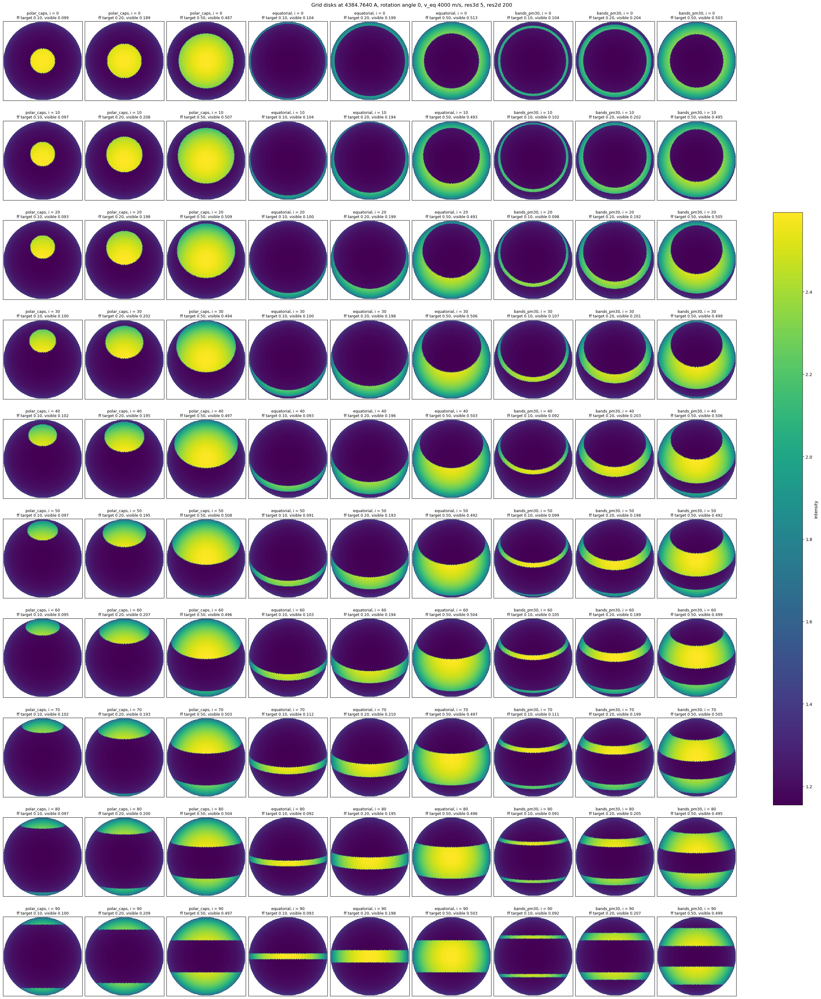

Line window 4368.480-4369.438 A: 110 bins
Line window 4376.859-4377.459 A: 69 bins
Line window 4380.160-4380.760 A: 69 bins
Random disk: 112 faculae, r = 5 deg, i = 45, visible ff 0.1993, seed 0
chi^2 over 248 bins in 3 line windows, free vertical offset fitted on those bins
rank run                          visible ff        chi^2
   1 polar_caps_ff0.10_i50            0.0970  1.72054e+00
   2 equatorial_ff0.10_i50            0.0912  1.83942e+00
   3 equatorial_ff0.20_i50            0.1928  1.86818e+00
   4 polar_caps_ff0.20_i50            0.1945  2.05249e+00
   5 bands_pm30_ff0.10_i50            0.0986  2.26373e+00
   6 bands_pm30_ff0.50_i40            0.5064  2.64316e+00
   7 bands_pm30_ff0.20_i50            0.1979  2.84142e+00
   8 bands_pm30_ff0.20_i40            0.2029  3.06312e+00
   9 polar_caps_ff0.50_i40            0.4968  3.13028e+00
  10 polar_caps_ff0.20_i40            0.1955  3.17577e+00
  11 equatorial_ff0.50_i50            0.4923  3.73382e+00
  12 polar_caps_ff0.10_i40  

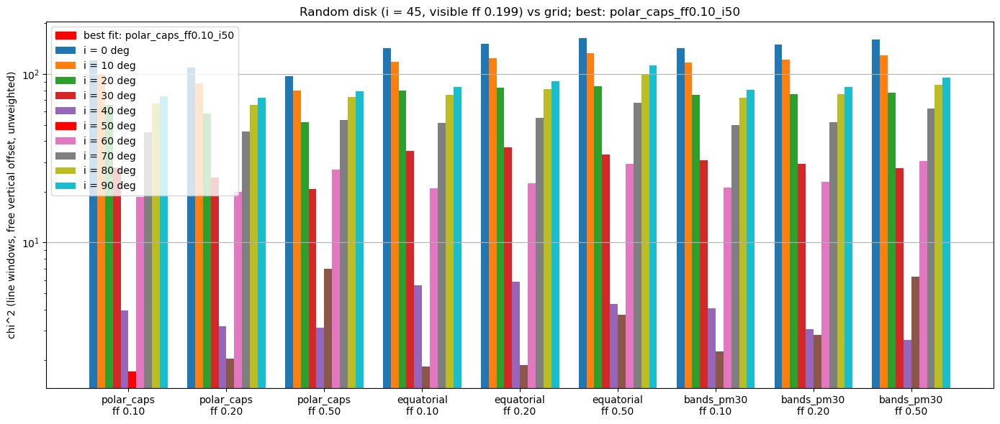

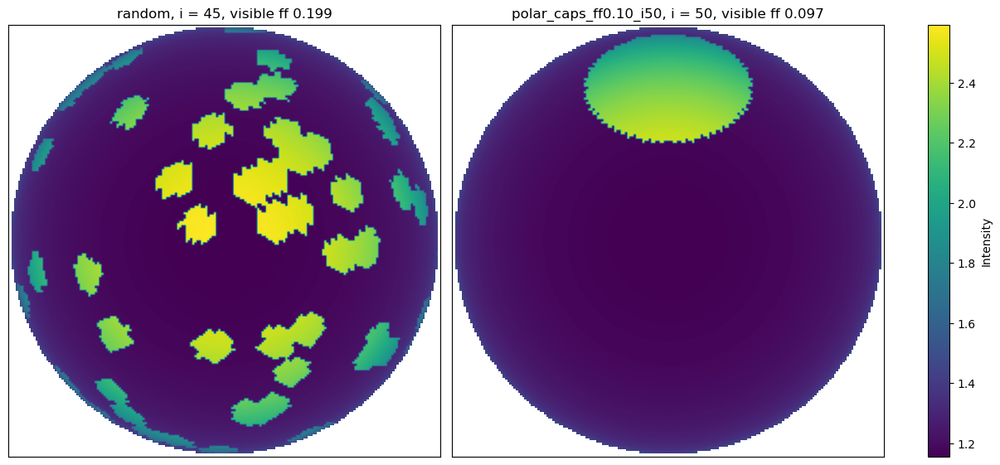

Contrast plot: no quiet run at i = 45, random not shown


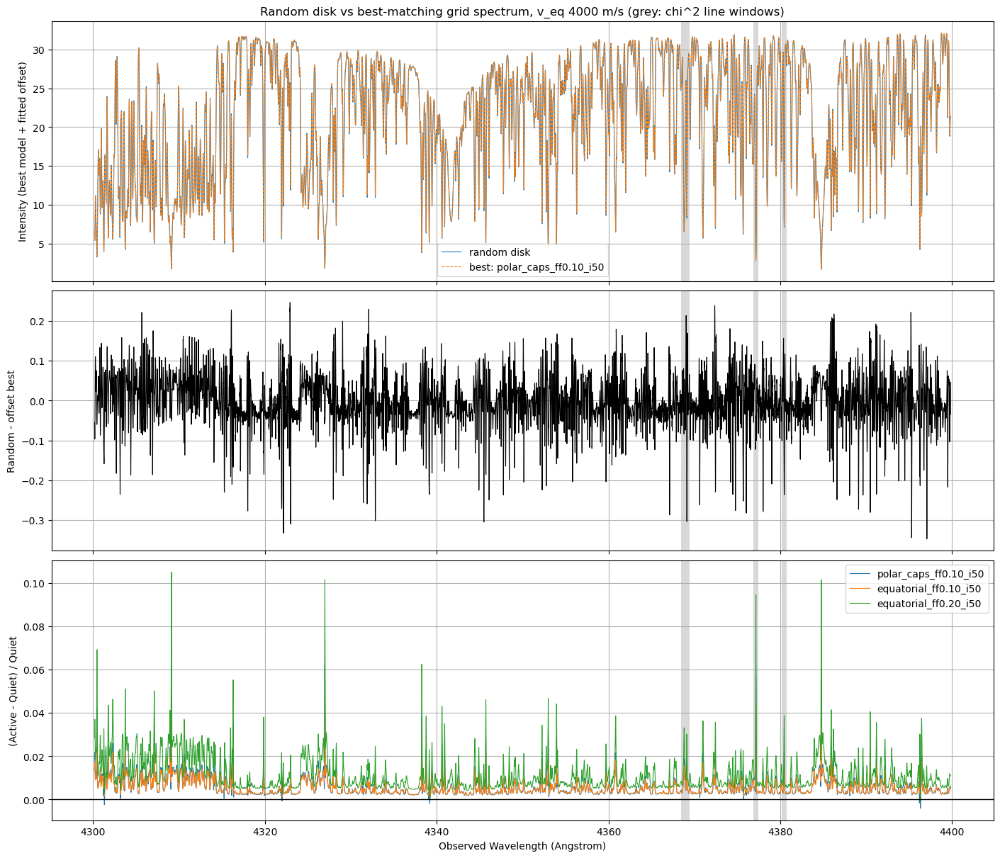

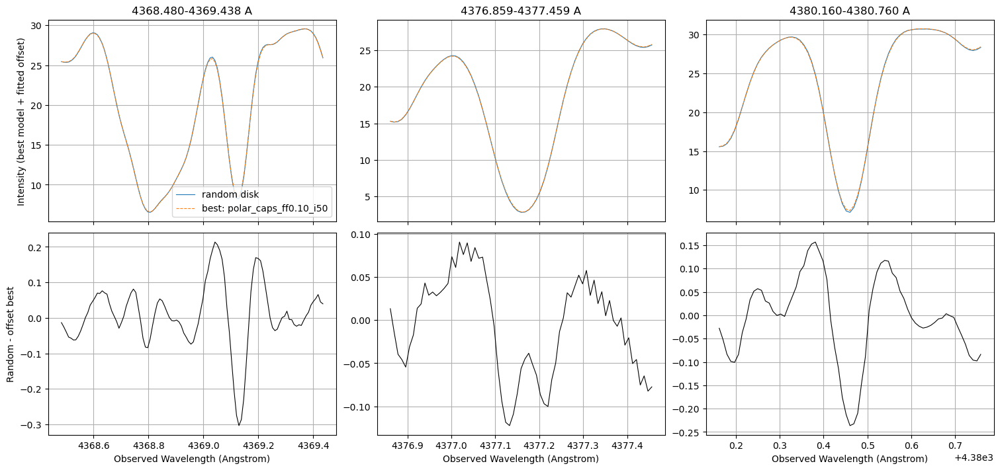

In [2]:
# ===== 1.4_gridsearch: extreme facular geometries at v_eq = 4000 m/s, chi^2 with a free vertical offset over three strong-line windows =====
# Forward-models a grid of axisymmetric facular geometries (polar caps, equatorial band,
# bands at +/-30 deg), each tuned to a target VISIBLE-disk filling factor at i = 0, 45, 90,
# then makes a disk with randomly placed faculae and finds the grid spectrum with the lowest
# chi^2 against it.
#
# Photosphere: the real SSD (with lines), NOT the continuum SSD used above. The continuum file
# is one flat level per mu from the 437.0-438.4 nm maximum, ~5x the SSD intensity near 430 nm,
# so it is not a quiet star over the whole range.
#
# Disks are not written per wavelength: disk_save would be ~11,500 files x 320 kB per run
# (>100 GB for the grid on /rds). Each disk is Doppler-shifted and binned into the spectrum as
# it is made, with exactly the steps of disk_utils.process_disk_directory (checked against
# sim_spectrum(disk_save=...) + process_disk_directory on the 4376 A window: identical bins,
# max relative difference 2e-14, i.e. summation order). Only the spectra and one image per run
# are cached, to a new file that is never overwritten.
import time
import actress as ac
import actress.run_actress_notebook as actr

grid_phot_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'   # real SSD, with lines
grid_fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
grid_phot_ld_file = 'test_phot_ssd_4300_4400_new.txt'
grid_fac_ld_file = 'test_fac_200G_4300_4400_new.txt'
grid_ld_law = 'power2'
# The files span 430.00034-440.00055 nm. contrast() takes delta_freq from both neighbours of
# each kept sample, so the two end samples cannot be used; start and stop one sample inside.
grid_wav_lower = 4.3001e-7   # m
grid_wav_higher = 4.3999e-7  # m

grid_v_eq = 4000                  # m/s, equatorial rotation velocity, fixed for every run
grid_incs = [0,10,20,30,40,50,60,70,80, 90]           # deg, i = 90 is equator-on; at i = 0 the strip pole lat = +90 faces us
grid_target_ffs = [0.10, 0.20, 0.50]   # visible-disk filling factor, sim.getdiscfill at rotation angle 0
grid_geometries = ['polar_caps', 'equatorial', 'bands_pm30']
grid_res3d = 5                    # healpix nside = 2^5
grid_res2d = 200                  # pixels across the projected disk
# At nside 32 the visible ff moves in steps of up to ~0.026 (one healpix ring), so the target
# can only be hit to about half a step. Anything further off means the solver failed.
grid_ff_tolerance = 0.02
grid_n_workers = 8                # processes; this runs on a shared login node

# Random-faculae test disk: circular faculae uniform on the sphere, added one at a time until
# the visible ff reaches the target, keeping whichever count lands closer to it.
grid_random_inc = 45              # deg
grid_random_r = 5                 # deg, facula radius
grid_random_seed = 0
grid_random_target_ff = 0.20

grid_cache_file = (f'./outputs/gridsearch/1_gridsearch_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                   f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}_randomseed{grid_random_seed}'
                   f'_incs{grid_incs[0]}-{grid_incs[-1]}x{len(grid_incs)}.npz')

# ----- limb-darkening fits over 430-440 nm, every native sample -----
grid_file_wav_nm = pd.read_csv(grid_phot_file, sep=r'\s+', comment='#').values[:, 0]   # nm
grid_log_grid_wav = contrst.wav_nm_to_m(contrst.log_uniform_grid(grid_file_wav_nm, R=500000))   # m, the grid contrast() uses
grid_indx_low, grid_indx_high = contrst.wav_limits(list(grid_log_grid_wav), grid_wav_lower, grid_wav_higher)
if grid_indx_low < 1 or grid_indx_high > len(grid_log_grid_wav) - 2:
    raise ValueError(f"Window indices {grid_indx_low}-{grid_indx_high} leave no neighbour for delta_freq")
# N such that contrast()'s step round((high - low) / N) is 1: every 0.0087 A (~600 m/s) sample is
# kept, rather than every 2nd as in the 4376 cells, so the 4000 m/s broadening spans ~13 bins.
grid_N_ld = grid_indx_high - grid_indx_low

contrst.validate_inputs(grid_fac_file, grid_phot_file, grid_wav_lower, grid_wav_higher, graphs=False)
for source_file, ld_file in ((grid_phot_file, grid_phot_ld_file), (grid_fac_file, grid_fac_ld_file)):
    if os.path.exists(ld_file):
        print(f"Using existing {ld_file}")
        continue
    t_start = time.time()
    contrst.contrast(source_file, wav_lower=grid_wav_lower, wav_higher=grid_wav_higher, N=grid_N_ld,
                     ld_law=grid_ld_law, save=ld_file, graphs=False)
    print(f"Wrote {ld_file} ({time.time() - t_start:.0f} s)")
contrst.validate_outputs(grid_fac_ld_file, grid_phot_ld_file, graphs=False)

grid_phot_ld = np.loadtxt(grid_phot_ld_file)   # columns: wavelength (m), I0, c1, c2
grid_fac_ld = np.loadtxt(grid_fac_ld_file)
if len(grid_phot_ld) != grid_indx_high - grid_indx_low + 1:
    raise ValueError(f"{grid_phot_ld_file} has {len(grid_phot_ld)} rows, expected every sample "
                     f"{grid_indx_low}-{grid_indx_high}; it was made with different settings")

# Wavelength labels exactly as run_actress_notebook formats them, and the bins
# process_disk_directory builds from them: centres are the sampled wavelengths themselves.
grid_wavelength_texts = [f"{wav * 1e10:.4f}" for wav in grid_phot_ld[:, 0]]
grid_input_wavelengths = np.array([float(text) for text in grid_wavelength_texts])   # Angstrom
grid_midpoints = 0.5 * (grid_input_wavelengths[:-1] + grid_input_wavelengths[1:])
grid_bin_edges = np.concatenate((
    [grid_input_wavelengths[0] - (grid_input_wavelengths[1] - grid_input_wavelengths[0]) / 2],
    grid_midpoints,
    [grid_input_wavelengths[-1] + (grid_input_wavelengths[-1] - grid_input_wavelengths[-2]) / 2]))
grid_bin_edges_rounded = np.round(grid_bin_edges, 10)

# Images are shown where the facula is brightest relative to the photosphere at disk centre.
grid_image_index = int(np.argmax(grid_fac_ld[:, 1] / grid_phot_ld[:, 1]))
print(f"{len(grid_input_wavelengths)} wavelengths, {grid_input_wavelengths[0]:.4f}-{grid_input_wavelengths[-1]:.4f} A; "
      f"images at {grid_input_wavelengths[grid_image_index]:.4f} A "
      f"(I0_fac / I0_phot = {grid_fac_ld[grid_image_index, 1] / grid_phot_ld[grid_image_index, 1]:.3f})")

_grid_ld_params = actr.Transitparams()
_grid_ld_params.ld = grid_ld_law
grid_ld_func = actr.Transitsim(_grid_ld_params).ld_law   # the same law function sim_spectrum passes to actress


# ----- geometry -----
def band_strips(geometry, half_width):
    """(lower, upper) addstrip latitudes in deg for a band family of half-width `half_width` (deg)."""
    if geometry == 'polar_caps':
        return [(-90, -90 + half_width), (90 - half_width, 90)]
    if geometry == 'equatorial':
        return [(-half_width, half_width)]
    if geometry == 'bands_pm30':
        return [(30 - half_width, 30 + half_width), (-30 - half_width, -30 + half_width)]
    raise ValueError(f"Unknown geometry {geometry}")

# Beyond these half-widths a band edge passes a pole and addstrip reflects it back silently.
grid_max_half_width = {'polar_caps': 90, 'equatorial': 90, 'bands_pm30': 60}   # deg


def build_grid_simulator(strips, faculae):
    """actress Simulator with the given strips [(lower, upper)] and faculae [(r, lon, lat)], deg."""
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[])   # explicit lists: the defaults are shared between instances
    sim.setxsize(grid_res2d)
    sim.setresolution(grid_res3d)
    for lower, upper in strips:
        if lower < -90 or upper > 90:
            raise ValueError(f"Strip ({lower}, {upper}) leaves +/-90 deg and would be reflected by addstrip")
        sim.addstrip(lower=lower, upper=upper, feature='fac')
    for r, lon, lat in faculae:
        sim.addfeature(r=r, lon=lon, lat=lat, feature='fac')
    return sim


def visible_fill(strips, faculae, inc):
    return build_grid_simulator(strips, faculae).getdiscfill(feature='fac', inc=inc)


def solve_half_width(geometry, inc, target_ff):
    """Half-width (deg) whose visible ff is closest to target_ff, by bisection (ff grows with width)."""
    lower, upper = 0.0, float(grid_max_half_width[geometry])
    if visible_fill(band_strips(geometry, upper), [], inc) < target_ff:
        raise ValueError(f"{geometry} at i = {inc} cannot reach visible ff {target_ff}")
    for _ in range(40):
        middle = (lower + upper) / 2
        if visible_fill(band_strips(geometry, middle), [], inc) < target_ff:
            lower = middle
        else:
            upper = middle
    # ff is a step function of width (whole healpix pixels), so take the closer side of the step.
    ff_lower = visible_fill(band_strips(geometry, lower), [], inc)
    ff_upper = visible_fill(band_strips(geometry, upper), [], inc)
    if abs(ff_lower - target_ff) < abs(ff_upper - target_ff):
        half_width, ff = lower, ff_lower
    else:
        half_width, ff = upper, ff_upper
    if abs(ff - target_ff) > grid_ff_tolerance:
        raise ValueError(f"{geometry} at i = {inc}: closest visible ff {ff:.4f} misses target {target_ff}")
    return half_width, ff


def place_random_faculae(inc, radius, seed, target_ff):
    """Faculae [(r, lon, lat)] drawn uniformly on the sphere until the visible ff is closest to target_ff."""
    rng = np.random.default_rng(seed)
    faculae = []
    ff = 0.0
    while ff < target_ff:
        lon = rng.uniform(0, 360)                        # deg
        lat = np.degrees(np.arcsin(rng.uniform(-1, 1)))  # deg, uniform in sin(lat) = uniform area
        faculae.append((radius, lon, lat))
        ff_previous = ff
        ff = visible_fill([], faculae, inc)
        if len(faculae) > 5000:
            raise RuntimeError(f"5000 faculae give only visible ff {ff:.4f}")
    if abs(ff_previous - target_ff) < abs(ff - target_ff):
        faculae = faculae[:-1]
        ff = ff_previous
    return faculae, ff


# ----- spectrum of one run, binned as process_disk_directory does -----
def set_grid_ld(sim, k):
    """Limb-darkening dict for wavelength row k, built as Transitsim.actress_run builds it."""
    sim.setld({'phot': [grid_phot_ld[k, 1], grid_phot_ld[k, 2], grid_phot_ld[k, 3], None, None],
               'spot': [12955331.717385203, 0.3, 0.2, 0.1, 0.1],   # unused in faconly mode
               'fac': [grid_fac_ld[k, 1], grid_fac_ld[k, 2], grid_fac_ld[k, 3], None, None],
               'func': grid_ld_func})


def simulate_grid_spectrum(run):
    """
    Disk-integrated spectrum at rotation angle 0 for one run.

    Returns (bin_centers (A), mean intensity per bin, disk image at grid_image_index).
    Same steps as disk_utils.process_disk_directory: shift each on-disk pixel by its Doppler
    shift, drop points within max_shift of the window ends, bin to the input wavelengths
    (edges rounded to 1e-10 A), keep only bins fully inside the trimmed range, average.
    """
    sim = build_grid_simulator(run['strips'], run['faculae'])
    n_bins = len(grid_input_wavelengths)
    # The shift map is -lambda v_los / c, so its maximum is at the longest wavelength; it is
    # needed before the loop to trim points exactly as process_disk_directory does.
    set_grid_ld(sim, n_bins - 1)
    _, shift_longest = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=grid_wavelength_texts[-1], returndisc=True)
    max_shift = shift_longest.max()   # A
    trim_lower = grid_input_wavelengths.min() + max_shift
    trim_upper = grid_input_wavelengths.max() - max_shift

    sums = np.zeros(n_bins)
    counts = np.zeros(n_bins, dtype=np.int64)
    largest_shift_seen = -np.inf
    image = None
    for k, wavelength_text in enumerate(grid_wavelength_texts):
        set_grid_ld(sim, k)
        disks, shift = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=wavelength_text, returndisc=True)
        disk = disks[0]
        largest_shift_seen = max(largest_shift_seen, shift.max())
        on_disk = disk > 0   # rotate_lc sets the off-disk background to 0
        observed_wavelength = grid_input_wavelengths[k] + shift[on_disk]
        intensity = disk[on_disk]
        kept = (observed_wavelength >= trim_lower) & (observed_wavelength <= trim_upper)
        point_bins = np.searchsorted(grid_bin_edges_rounded, np.round(observed_wavelength[kept], 10), side='right') - 1
        in_range = (point_bins >= 0) & (point_bins < n_bins)
        sums += np.bincount(point_bins[in_range], weights=intensity[kept][in_range], minlength=n_bins)
        counts += np.bincount(point_bins[in_range], minlength=n_bins)
        if k == grid_image_index:
            image = disk.copy()

    if largest_shift_seen != max_shift:
        raise ValueError(f"{run['name']}: max shift {largest_shift_seen} is not at the longest wavelength ({max_shift})")
    valid_bins = (grid_bin_edges[:-1] >= trim_lower) & (grid_bin_edges[1:] <= trim_upper)
    if np.any(counts[valid_bins] == 0):
        raise ValueError(f"{run['name']}: {np.sum(counts[valid_bins] == 0)} empty wavelength bins")
    return grid_input_wavelengths[valid_bins], sums[valid_bins] / counts[valid_bins], image


# ----- define every run -----
grid_runs = []
for geometry in grid_geometries:
    for inc in grid_incs:
        for target_ff in grid_target_ffs:
            half_width, ff = solve_half_width(geometry, inc, target_ff)
            grid_runs.append({'name': f'{geometry}_ff{target_ff:.2f}_i{inc}', 'kind': 'grid', 'geometry': geometry,
                              'inc': inc, 'target_ff': target_ff, 'visible_ff': ff, 'half_width': half_width,
                              'strips': band_strips(geometry, half_width), 'faculae': []})
for inc in grid_incs:
    grid_runs.append({'name': f'quiet_i{inc}', 'kind': 'quiet', 'geometry': 'quiet', 'inc': inc, 'target_ff': 0.0,
                      'visible_ff': 0.0, 'half_width': 0.0, 'strips': [], 'faculae': []})
random_faculae, random_ff = place_random_faculae(grid_random_inc, grid_random_r, grid_random_seed, grid_random_target_ff)
grid_runs.append({'name': 'random', 'kind': 'random', 'geometry': 'random', 'inc': grid_random_inc,
                  'target_ff': grid_random_target_ff, 'visible_ff': random_ff, 'half_width': np.nan,
                  'strips': [], 'faculae': random_faculae})

print(f"\n{'run':28s} {'half-width (deg)':>16s} {'target ff':>9s} {'visible ff':>10s}  strips (lower, upper) deg")
for run in grid_runs:
    strips_text = ', '.join(f'({lower:.2f}, {upper:.2f})' for lower, upper in run['strips'])
    print(f"{run['name']:28s} {run['half_width']:16.3f} {run['target_ff']:9.2f} {run['visible_ff']:10.4f}  {strips_text}")
print(f"random: {len(random_faculae)} faculae of r = {grid_random_r} deg, seed {grid_random_seed}, i = {grid_random_inc}")

# ----- simulate, or load the cache -----
grid_run_names = np.array([run['name'] for run in grid_runs])
grid_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths), grid_random_seed,
                        grid_random_r, grid_random_inc, len(random_faculae)], dtype=float)
grid_half_widths = np.array([run['half_width'] for run in grid_runs])
grid_spectra = {}
if os.path.exists(grid_cache_file):
    cached = np.load(grid_cache_file)
    if not (np.array_equal(cached['run_names'], grid_run_names) and np.array_equal(cached['config'], grid_config)
            and np.allclose(cached['half_widths'], grid_half_widths, equal_nan=True)):
        raise ValueError(f"{grid_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in grid_run_names:
        grid_spectra[name] = (cached[f'bins_{name}'], cached[f'spectrum_{name}'], cached[f'image_{name}'])
    print(f"\nLoaded {len(grid_spectra)} spectra from {grid_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=grid_n_workers) as pool:
        results = pool.map(simulate_grid_spectrum, grid_runs, chunksize=1)
    for run, result in zip(grid_runs, results):
        grid_spectra[run['name']] = result
    print(f"\nSimulated {len(grid_runs)} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    os.makedirs(os.path.dirname(grid_cache_file), exist_ok=True)
    to_save = {'run_names': grid_run_names, 'config': grid_config, 'half_widths': grid_half_widths,
               'visible_ffs': np.array([run['visible_ff'] for run in grid_runs]),
               'random_faculae': np.array(random_faculae)}   # (r, lon, lat) deg, addfeature convention
    for name, (bins, spectrum, image) in grid_spectra.items():
        to_save[f'bins_{name}'] = bins
        to_save[f'spectrum_{name}'] = spectrum
        to_save[f'image_{name}'] = image
    np.savez(grid_cache_file, **to_save)
    print(f"Wrote {grid_cache_file}")

for name, (bins, spectrum, image) in grid_spectra.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")

# ----- disk images of every grid scenario -----
def masked_image(name):
    image = grid_spectra[name][2].copy()
    image[image == 0] = np.nan   # off-disk background
    return image

grid_names = [run['name'] for run in grid_runs if run['kind'] == 'grid']
image_vmin = min(np.nanmin(masked_image(name)) for name in grid_run_names)
image_vmax = max(np.nanmax(masked_image(name)) for name in grid_run_names)
scenario_columns = [(geometry, target_ff) for geometry in grid_geometries for target_ff in grid_target_ffs]
fig, axes = plt.subplots(len(grid_incs), len(scenario_columns), figsize=(3 * len(scenario_columns), 3.3 * len(grid_incs)),
                         squeeze=False, constrained_layout=True)
runs_by_name = {run['name']: run for run in grid_runs}
for row, inc in enumerate(grid_incs):
    for column, (geometry, target_ff) in enumerate(scenario_columns):
        run = runs_by_name[f'{geometry}_ff{target_ff:.2f}_i{inc}']
        ax = axes[row, column]
        im = ax.imshow(masked_image(run['name']), cmap='viridis', vmin=image_vmin, vmax=image_vmax)
        ax.set_title(f"{geometry}, i = {inc}\nff target {target_ff:.2f}, visible {run['visible_ff']:.3f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), label='Intensity', shrink=0.6)
fig.suptitle(f"Grid disks at {grid_input_wavelengths[grid_image_index]:.4f} A, rotation angle 0, v_eq {grid_v_eq} m/s, "
             f"res3d {grid_res3d}, res2d {grid_res2d}")
plt.show()

# ----- chi^2 of the random disk against every grid spectrum -----
# Spectra keep their raw intensity (no normalisation); chi^2 minimizes over a free additive vertical offset.
# The common bins are those left after the i = 90 edge trimming (largest Doppler shift).
common_bins = grid_spectra['random'][0]
for name in grid_names:
    common_bins = np.intersect1d(common_bins, grid_spectra[name][0])

# chi^2 uses only the bins around three strong lines. Line centres are minima of the cached quiet_i0
# spectrum; the first region spans the 4368.797 + 4369.130 A pair. The +/-0.3 A padding covers the
# +/-0.064 A rotational broadening at 4000 m/s (4380 A x 4000 / c) plus the line wings.
line_window_padding = 0.3   # A
line_window_regions = [(4368.780, 4369.138), (4377.159, 4377.159), (4380.460, 4380.460)]   # A, (start, end) before padding
line_windows = [(start - line_window_padding, end + line_window_padding) for start, end in line_window_regions]
in_line_windows = np.zeros(len(common_bins), dtype=bool)
for lower, upper in line_windows:
    in_window = (common_bins >= lower) & (common_bins <= upper)
    if not np.any(in_window):
        raise ValueError(f"No common bins in the line window {lower:.3f}-{upper:.3f} A")
    if np.any(in_line_windows & in_window):
        raise ValueError(f"Line window {lower:.3f}-{upper:.3f} A overlaps another window")
    in_line_windows |= in_window
    print(f"Line window {lower:.3f}-{upper:.3f} A: {in_window.sum()} bins")


def shade_line_windows(ax):
    for lower, upper in line_windows:
        ax.axvspan(lower, upper, color='grey', alpha=0.3, linewidth=0)


def spectrum_on_common_bins(name):
    bins, spectrum, _ = grid_spectra[name]
    on_common = np.isin(bins, common_bins)
    return spectrum[on_common]

random_spectrum = spectrum_on_common_bins('random')
random_line_spectrum = random_spectrum[in_line_windows]
chi2_by_name = {}
offset_by_name = {}
for name in grid_names:
    model = spectrum_on_common_bins(name)[in_line_windows]
    # The least-squares additive offset is the mean residual over the line bins.
    offset = np.mean(random_line_spectrum - model)
    chi2_by_name[name] = np.sum((random_line_spectrum - (model + offset)) ** 2)
    offset_by_name[name] = offset
ranked_names = sorted(chi2_by_name, key=chi2_by_name.get)
best_name = ranked_names[0]

print(f"Random disk: {len(random_faculae)} faculae, r = {grid_random_r} deg, i = {grid_random_inc}, visible ff {random_ff:.4f}, "
      f"seed {grid_random_seed}")
print(f"chi^2 over {in_line_windows.sum()} bins in {len(line_windows)} line windows, free vertical offset fitted on those bins")
print(f"{'rank':>4s} {'run':28s} {'visible ff':>10s} {'chi^2':>12s}")
for rank, name in enumerate(ranked_names, start=1):
    print(f"{rank:4d} {name:28s} {runs_by_name[name]['visible_ff']:10.4f} {chi2_by_name[name]:12.5e}")

fig, fig_ax = plt.subplots(figsize=(14, 6))
bar_width = 0.8 / len(grid_incs)
x_positions = np.arange(len(scenario_columns))
for offset, inc in enumerate(grid_incs):
    chi2_values = [chi2_by_name[f'{geometry}_ff{target_ff:.2f}_i{inc}'] for geometry, target_ff in scenario_columns]
    bars = fig_ax.bar(x_positions + (offset - (len(grid_incs) - 1) / 2) * bar_width, chi2_values, width=bar_width, label=f'i = {inc} deg')
    # Lowest chi^2 over the whole grid: the numerical best fit
    for bar, (geometry, target_ff) in zip(bars, scenario_columns):
        if f'{geometry}_ff{target_ff:.2f}_i{inc}' == best_name:
            bar.set_color('red')
            bar.set_label(f"best fit: {best_name}")
fig_ax.set_xticks(x_positions)
fig_ax.set_xticklabels([f'{geometry}\nff {target_ff:.2f}' for geometry, target_ff in scenario_columns])
fig_ax.set_yscale('log')
fig_ax.set_ylabel('chi^2 (line windows, free vertical offset, unweighted)')
fig_ax.set_title(f'Random disk (i = {grid_random_inc}, visible ff {random_ff:.3f}) vs grid; best: {best_name}')
fig_ax.legend()
fig_ax.grid(True, axis='y')
plt.tight_layout()
plt.show()
# ----- random disk vs best match -----
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, name in zip(axes, ['random', best_name]):
    im = ax.imshow(masked_image(name), cmap='viridis', vmin=image_vmin, vmax=image_vmax)
    ax.set_title(f"{name}, i = {runs_by_name[name]['inc']}, visible ff {runs_by_name[name]['visible_ff']:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes.tolist(), label='Intensity')
plt.show()

# Contrast against the quiet star at each run's own inclination isolates the facular signal,
# which the normalised spectra (dominated by the photospheric lines) hide.
def contrast_to_quiet(name):
    quiet_name = f"quiet_i{runs_by_name[name]['inc']}"
    bins, spectrum, _ = grid_spectra[name]
    quiet_bins, quiet_spectrum, _ = grid_spectra[quiet_name]
    if not np.array_equal(bins, quiet_bins):
        raise ValueError(f"Bins of {name} and {quiet_name} differ")
    on_common = np.isin(bins, common_bins)
    return (spectrum[on_common] - quiet_spectrum[on_common]) / quiet_spectrum[on_common]

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, constrained_layout=True)
axes[0].plot(common_bins, random_spectrum, linewidth=0.8, label='random disk')
best_offset = spectrum_on_common_bins(best_name) + offset_by_name[best_name]
axes[0].plot(common_bins, best_offset, linewidth=0.8, linestyle='--', label=f'best: {best_name}')
axes[0].set_ylabel('Intensity (best model + fitted offset)')
axes[1].plot(common_bins, random_spectrum - best_offset, linewidth=0.8, color='k')
axes[1].set_ylabel('Random - offset best')
for name in ['random'] + ranked_names[:3]:
    # The grid has no quiet run at every inclination (e.g. the random disk at i = 45), so say which are left out.
    if f"quiet_i{runs_by_name[name]['inc']}" not in grid_spectra:
        print(f"Contrast plot: no quiet run at i = {runs_by_name[name]['inc']}, {name} not shown")
        continue
    axes[2].plot(common_bins, contrast_to_quiet(name), linewidth=0.8, label=name)
axes[2].axhline(0, color='k', linewidth=1)
axes[2].set_ylabel('(Active - Quiet) / Quiet')
axes[2].set_xlabel('Observed Wavelength (Angstrom)')
for ax in axes:
    shade_line_windows(ax)
    ax.grid(True)
    if ax.get_legend_handles_labels()[0]:
        ax.legend()
axes[0].set_title(f'Random disk vs best-matching grid spectrum, v_eq {grid_v_eq} m/s (grey: chi^2 line windows)')
plt.show()

# ----- the fitted line windows, zoomed -----
fig, axes = plt.subplots(2, len(line_windows), figsize=(5 * len(line_windows), 7), sharex='col', squeeze=False,
                         constrained_layout=True)
for column, (lower, upper) in enumerate(line_windows):
    in_window = (common_bins >= lower) & (common_bins <= upper)
    axes[0, column].plot(common_bins[in_window], random_spectrum[in_window], linewidth=0.8, label='random disk')
    axes[0, column].plot(common_bins[in_window], best_offset[in_window], linewidth=0.8, linestyle='--',
                         label=f'best: {best_name}')
    axes[1, column].plot(common_bins[in_window], random_spectrum[in_window] - best_offset[in_window], linewidth=0.8, color='k')
    axes[0, column].set_title(f'{lower:.3f}-{upper:.3f} A')
    axes[1, column].set_xlabel('Observed Wavelength (Angstrom)')
    for ax in axes[:, column]:
        ax.grid(True)
axes[0, 0].set_ylabel('Intensity (best model + fitted offset)')
axes[1, 0].set_ylabel('Random - offset best')
axes[0, 0].legend()
plt.show()


Nearest sample: 4377.0010 A (row 8863); I0_phot = 34.59, I0_fac = 34.48, I0_fac / I0_phot = 0.9967


/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py:63: RuntimeWarning: divide by zero encountered in power
  y = I0 * (1-(a*(1-(mu**b))))


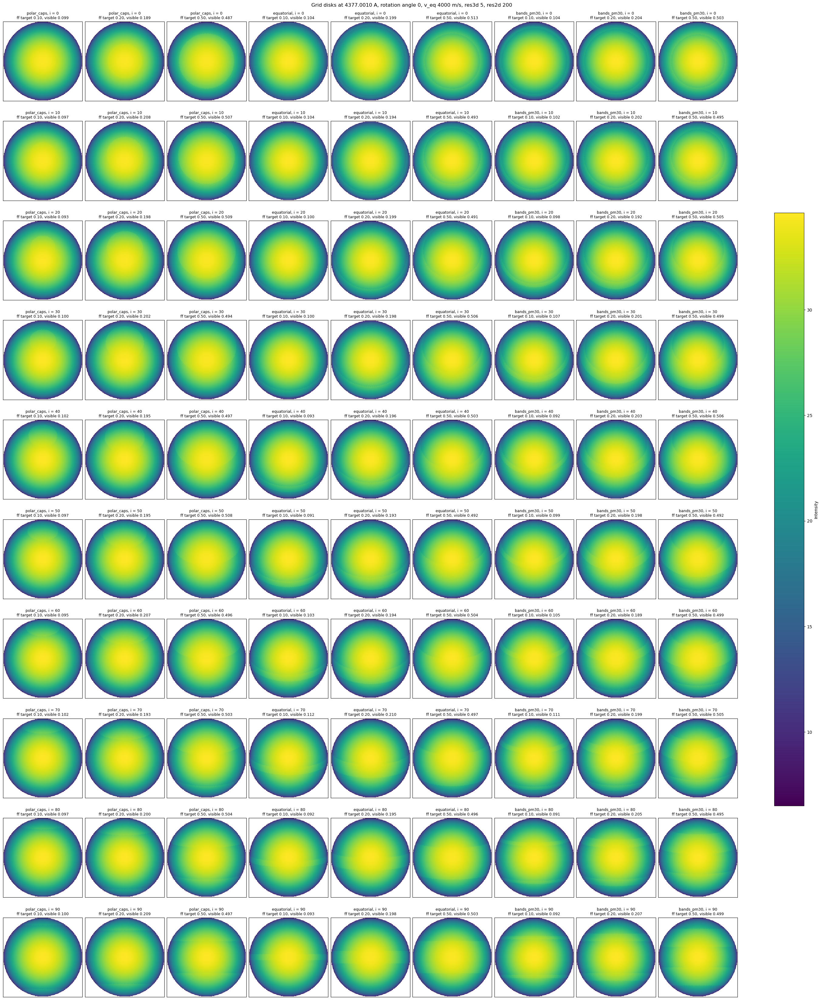

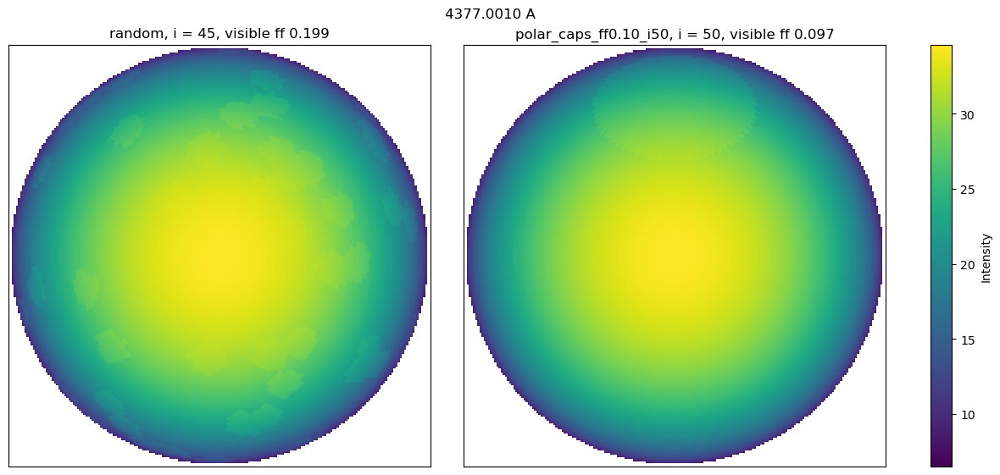

In [3]:
# ===== disk images at a chosen wavelength =====
# The cache holds one image per run, at grid_image_index only. Images at any other wavelength are
# re-rendered here: one disk per run at rotation angle 0, at the emitted (unshifted) wavelength,
# exactly as simulate_grid_spectrum makes the cached image. Nothing is written to disk.
# Uses the functions and runs from the 1_gridsearch cell above.
chosen_image_wavelength = 4377.0   # A

if not grid_input_wavelengths[0] <= chosen_image_wavelength <= grid_input_wavelengths[-1]:
    raise ValueError(f"{chosen_image_wavelength} A is outside the "
                     f"{grid_input_wavelengths[0]:.4f}-{grid_input_wavelengths[-1]:.4f} A window")
chosen_index = int(np.argmin(np.abs(grid_input_wavelengths - chosen_image_wavelength)))
print(f"Nearest sample: {grid_input_wavelengths[chosen_index]:.4f} A (row {chosen_index}); "
      f"I0_phot = {grid_phot_ld[chosen_index, 1]:.4g}, I0_fac = {grid_fac_ld[chosen_index, 1]:.4g}, "
      f"I0_fac / I0_phot = {grid_fac_ld[chosen_index, 1] / grid_phot_ld[chosen_index, 1]:.4f}")


def render_disk_image(run, k):
    """Disk image of one run at wavelength row k, rotation angle 0, off-disk background set to NaN."""
    sim = build_grid_simulator(run['strips'], run['faculae'])
    set_grid_ld(sim, k)
    disks, _ = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                             wavelength=grid_wavelength_texts[k], returndisc=True)
    image = disks[0].copy()
    image[image == 0] = np.nan   # rotate_lc sets the off-disk background to 0
    return image


# Rendering at the cached wavelength must reproduce the cached image; otherwise the cache was made
# with different limb-darkening fits or settings, and the new images would not match the spectra.
check_image = render_disk_image(runs_by_name['random'], grid_image_index)
if not np.allclose(check_image, masked_image('random'), rtol=1e-12, atol=0, equal_nan=True):
    raise ValueError("Re-rendered 'random' image at grid_image_index differs from the cached one")

chosen_images = {}
for run in grid_runs:
    chosen_images[run['name']] = render_disk_image(run, chosen_index)
chosen_vmin = min(np.nanmin(image) for image in chosen_images.values())
chosen_vmax = max(np.nanmax(image) for image in chosen_images.values())

# ----- every grid scenario -----
fig, axes = plt.subplots(len(grid_incs), len(scenario_columns), figsize=(3 * len(scenario_columns), 3.3 * len(grid_incs)),
                         squeeze=False, constrained_layout=True)
for row, inc in enumerate(grid_incs):
    for column, (geometry, target_ff) in enumerate(scenario_columns):
        run = runs_by_name[f'{geometry}_ff{target_ff:.2f}_i{inc}']
        ax = axes[row, column]
        im = ax.imshow(chosen_images[run['name']], cmap='viridis', vmin=chosen_vmin, vmax=chosen_vmax)
        ax.set_title(f"{geometry}, i = {inc}\nff target {target_ff:.2f}, visible {run['visible_ff']:.3f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), label='Intensity', shrink=0.6)
fig.suptitle(f"Grid disks at {grid_input_wavelengths[chosen_index]:.4f} A, rotation angle 0, v_eq {grid_v_eq} m/s, "
             f"res3d {grid_res3d}, res2d {grid_res2d}")
plt.show()

# ----- random disk vs best match -----
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, name in zip(axes, ['random', best_name]):
    im = ax.imshow(chosen_images[name], cmap='viridis', vmin=chosen_vmin, vmax=chosen_vmax)
    ax.set_title(f"{name}, i = {runs_by_name[name]['inc']}, visible ff {runs_by_name[name]['visible_ff']:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes.tolist(), label='Intensity')
fig.suptitle(f"{grid_input_wavelengths[chosen_index]:.4f} A")
plt.show()

scenario                i (deg) visible ff redrawn  strips (lower, upper) deg
random_bands_seed1        59.21     0.3305       0  (-64.45, -26.30), (-31.73, -12.49), (31.58, 50.32)
random_bands_seed2        74.83     0.0681       0  (35.28, 42.59)
random_bands_seed3        85.09     0.1955       0  (24.57, 49.53)
random_bands_seed4        19.43     0.3730       0  (68.81, 75.72), (3.62, 21.18), (32.00, 42.28)
random_bands_seed5        36.39     0.1007       0  (-5.39, 8.90)
random_bands_seed6        57.44     0.2870       1  (-23.92, -6.44), (12.47, 28.34)
random_bands_seed7        51.31     0.3841       1  (27.41, 39.51), (-41.28, -5.83), (26.03, 46.87)
random_bands_seed8        70.91     0.2315       0  (-37.45, -5.06)
random_bands_seed9        29.51     0.7913       0  (-4.09, 27.90), (7.13, 44.08), (27.59, 64.65)
random_bands_seed10       17.06     0.1543       0  (36.38, 45.75)

Loaded 20 spectra from ./outputs/gridsearch/1_gridsearch_randombands_v4000_res3d5_res2d200_4300.1_4399.


random_bands_seed3: i = 85.09 deg, visible ff 0.1955, 1 band(s)
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.20_i90            0.2073  9.22815e-02
   2 bands_pm30_ff0.20_i80            0.2051  1.21033e-01
   3 equatorial_ff0.20_i80            0.1947  1.50329e-01
   4 bands_pm30_ff0.10_i90            0.0918  1.67811e-01
   5 equatorial_ff0.10_i90            0.0928  1.75579e-01

random_bands_seed4: i = 19.43 deg, visible ff 0.3730, 3 band(s)
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.50_i20            0.5049  2.01230e-01
   2 bands_pm30_ff0.20_i20            0.1922  4.79886e-01
   3 equatorial_ff0.50_i20            0.4907  7.47768e-01
   4 bands_pm30_ff0.10_i20            0.0982  9.21137e-01
   5 polar_caps_ff0.10_i20            0.0928  1.20427e+00

random_bands_seed5: i = 36.39 deg, visible ff 0.1007, 1 band(s)
rank run                          visible ff        chi^2
   1 equatorial_ff0.20_i40            0.1965  1.661


random_bands_seed7: i = 51.31 deg, visible ff 0.3841, 3 band(s)
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.50_i50            0.4921  3.13201e-01
   2 equatorial_ff0.50_i50            0.4923  4.12575e-01
   3 bands_pm30_ff0.20_i50            0.1979  6.89339e-01
   4 polar_caps_ff0.50_i50            0.5077  6.96245e-01
   5 polar_caps_ff0.20_i50            0.1945  1.09713e+00

random_bands_seed8: i = 70.91 deg, visible ff 0.2315, 1 band(s)
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.20_i70            0.1991  8.67492e-02
   2 bands_pm30_ff0.10_i70            0.1108  1.43315e-01
   3 equatorial_ff0.10_i70            0.1119  1.62290e-01
   4 polar_caps_ff0.20_i70            0.1934  2.76818e-01
   5 equatorial_ff0.20_i70            0.2103  3.02119e-01

random_bands_seed9: i = 29.51 deg, visible ff 0.7913, 3 band(s)
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.50_i30            0.4988  1.359

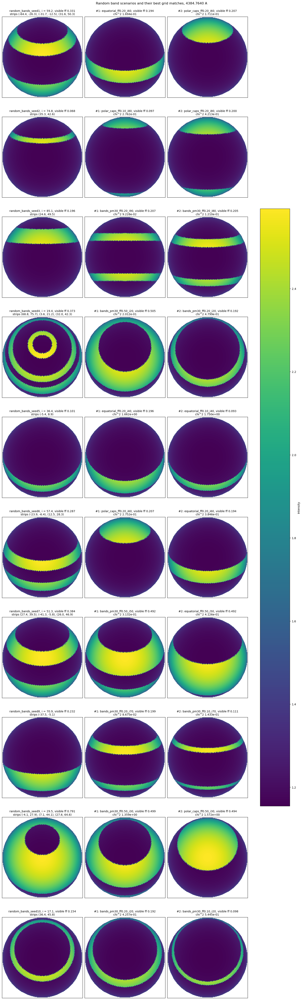

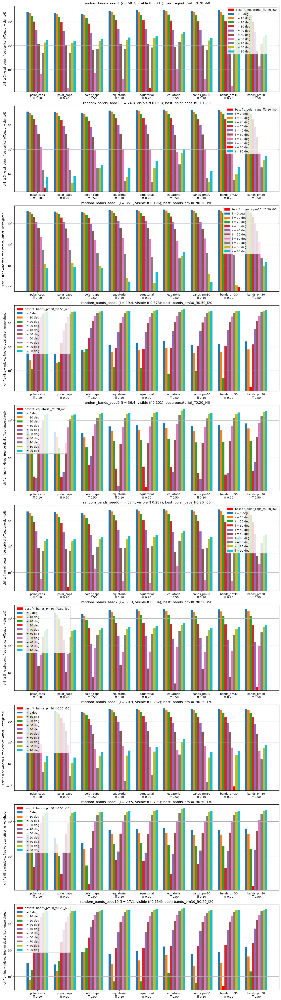

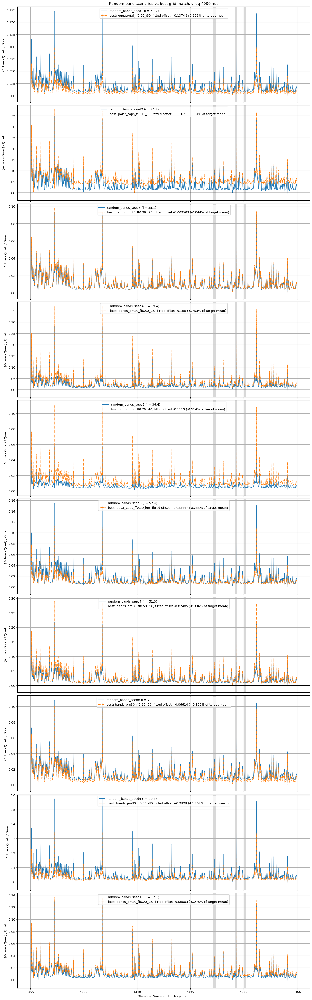

In [4]:
# ===== random facular band scenarios vs the grid =====
# Same chi^2 search as for the random faculae disk above, with targets made of randomly placed
# bands. Each scenario draws, from its own seed:
#   inclination       uniform in cos(i) over 0-90 deg (isotropic spin axes)
#   number of bands   uniform in {1, ..., band_n_max}
#   band centres      uniform in sin(lat) (uniform area), addstrip latitude convention
#                     (strip lat +90 is the pole facing us at i = 0)
#   band half-widths  uniform in band_half_width_range; NOT tuned, so the visible ff is whatever results
# A band with an edge beyond +/-90 is redrawn, because addstrip would reflect it silently.
# The grid only has i = 0, 45, 90, so inclination can be recovered only to that spacing.
# Uses the functions, grid spectra and common_bins from the cell above.
band_seeds = list(range(1, 11))   # 10 scenarios
band_n_max = 3
band_half_width_range = (2.0, 20.0)   # deg

band_cache_file = (f'./outputs/gridsearch/1_gridsearch_randombands_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                   f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}'
                   f'_seeds{band_seeds[0]}-{band_seeds[-1]}.npz')


def draw_random_bands(seed):
    """(inc (deg), strips [(lower, upper)] deg, number of redrawn bands) for one scenario."""
    rng = np.random.default_rng(seed)
    inc = np.degrees(np.arccos(rng.uniform(0, 1)))
    n_bands = int(rng.integers(1, band_n_max + 1))
    strips = []
    n_redrawn = 0
    while len(strips) < n_bands:
        centre = np.degrees(np.arcsin(rng.uniform(-1, 1)))
        half_width = rng.uniform(*band_half_width_range)
        if centre - half_width < -90 or centre + half_width > 90:
            n_redrawn += 1
            continue
        strips.append((centre - half_width, centre + half_width))
    return inc, strips, n_redrawn


band_runs = []
for seed in band_seeds:
    inc, strips, n_redrawn = draw_random_bands(seed)
    ff = visible_fill(strips, [], inc)
    band_runs.append({'name': f'random_bands_seed{seed}', 'kind': 'random_bands', 'seed': seed, 'inc': inc,
                      'visible_ff': ff, 'strips': strips, 'faculae': [], 'n_redrawn': n_redrawn})
    # Its own quiet star, for the contrast plot: the grid only has quiet runs at 0, 45, 90.
    band_runs.append({'name': f'quiet_random_bands_seed{seed}', 'kind': 'quiet', 'seed': seed, 'inc': inc,
                      'visible_ff': 0.0, 'strips': [], 'faculae': [], 'n_redrawn': 0})

print(f"{'scenario':22s} {'i (deg)':>8s} {'visible ff':>10s} {'redrawn':>7s}  strips (lower, upper) deg")
for run in band_runs:
    if run['kind'] != 'random_bands':
        continue
    strips_text = ', '.join(f'({lower:.2f}, {upper:.2f})' for lower, upper in run['strips'])
    print(f"{run['name']:22s} {run['inc']:8.2f} {run['visible_ff']:10.4f} {run['n_redrawn']:7d}  {strips_text}")
    if run['visible_ff'] == 0:
        print(f"  WARNING: {run['name']} has no band on the visible disk; its target is the quiet star")

# ----- simulate, or load the cache -----
band_run_names = np.array([run['name'] for run in band_runs])
band_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths), band_n_max,
                        band_half_width_range[0], band_half_width_range[1]], dtype=float)
band_strip_edges = np.array([edge for run in band_runs for strip in run['strips'] for edge in strip] +
                            [run['inc'] for run in band_runs])
band_spectra = {}
if os.path.exists(band_cache_file):
    cached = np.load(band_cache_file)
    if not (np.array_equal(cached['run_names'], band_run_names) and np.array_equal(cached['config'], band_config)
            and np.allclose(cached['strip_edges'], band_strip_edges, rtol=0, atol=1e-10)):   # deg; last-bit differences between CPUs
        raise ValueError(f"{band_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in band_run_names:
        band_spectra[name] = (cached[f'bins_{name}'], cached[f'spectrum_{name}'], cached[f'image_{name}'])
    print(f"\nLoaded {len(band_spectra)} spectra from {band_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=min(grid_n_workers, len(band_runs))) as pool:
        results = pool.map(simulate_grid_spectrum, band_runs, chunksize=1)
    for run, result in zip(band_runs, results):
        band_spectra[run['name']] = result
    print(f"\nSimulated {len(band_runs)} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    to_save = {'run_names': band_run_names, 'config': band_config, 'strip_edges': band_strip_edges,
               'incs': np.array([run['inc'] for run in band_runs]),
               'visible_ffs': np.array([run['visible_ff'] for run in band_runs])}
    for name, (bins, spectrum, image) in band_spectra.items():
        to_save[f'bins_{name}'] = bins
        to_save[f'spectrum_{name}'] = spectrum
        to_save[f'image_{name}'] = image
    np.savez(band_cache_file, **to_save)
    print(f"Wrote {band_cache_file}")

for name, (bins, spectrum, image) in band_spectra.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")

# ----- chi^2 of each scenario against every grid spectrum -----
# Same statistic as above: unnormalised spectra, free additive vertical offset fit against the target,
# both over the line-window bins only.
def normalise_on_common_bins(bins, spectrum, label):
    on_common = np.isin(bins, common_bins)
    if on_common.sum() != len(common_bins):
        raise ValueError(f"{label} does not cover all {len(common_bins)} common bins")
    return spectrum[on_common]

band_targets = [run for run in band_runs if run['kind'] == 'random_bands']
band_chi2 = {}
band_offsets = {}
band_target_means = {}
for target in band_targets:
    bins, spectrum, _ = band_spectra[target['name']]
    target_spectrum = normalise_on_common_bins(bins, spectrum, target['name'])
    target_line_spectrum = target_spectrum[in_line_windows]
    chi2_by_grid_name = {}
    offset_by_grid_name = {}
    for name in grid_names:
        model = spectrum_on_common_bins(name)[in_line_windows]
        offset = np.mean(target_line_spectrum - model)
        chi2_by_grid_name[name] = np.sum((target_line_spectrum - (model + offset)) ** 2)
        offset_by_grid_name[name] = offset
    band_chi2[target['name']] = chi2_by_grid_name
    band_offsets[target['name']] = offset_by_grid_name
    band_target_means[target['name']] = np.mean(target_spectrum)

    ranked = sorted(chi2_by_grid_name, key=chi2_by_grid_name.get)
    target['ranked'] = ranked
    print(f"\n{target['name']}: i = {target['inc']:.2f} deg, visible ff {target['visible_ff']:.4f}, "
          f"{len(target['strips'])} band(s)")
    print(f"{'rank':>4s} {'run':28s} {'visible ff':>10s} {'chi^2':>12s}")
    for rank, name in enumerate(ranked[:5], start=1):
        print(f"{rank:4d} {name:28s} {runs_by_name[name]['visible_ff']:10.4f} {chi2_by_grid_name[name]:12.5e}")
# ----- images: each scenario next to its two best matches -----
def masked_band_image(name):
    image = band_spectra[name][2].copy()
    image[image == 0] = np.nan   # off-disk background
    return image

fig, axes = plt.subplots(len(band_targets), 3, figsize=(15, 5 * len(band_targets)), squeeze=False, constrained_layout=True)
for row, target in enumerate(band_targets):
    strips_text = ', '.join(f'({lower:.1f}, {upper:.1f})' for lower, upper in target['strips'])
    panels = [(masked_band_image(target['name']),
               f"{target['name']}, i = {target['inc']:.1f}, visible ff {target['visible_ff']:.3f}\nstrips {strips_text}")]
    for rank, name in enumerate(target['ranked'][:2], start=1):
        panels.append((masked_image(name), f"#{rank}: {name}, visible ff {runs_by_name[name]['visible_ff']:.3f}\n"
                                           f"chi^2 {band_chi2[target['name']][name]:.3e}"))
    for ax, (image, title) in zip(axes[row], panels):
        im = ax.imshow(image, cmap='viridis', vmin=image_vmin, vmax=image_vmax)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), label='Intensity', shrink=0.6)
fig.suptitle(f'Random band scenarios and their best grid matches, {grid_input_wavelengths[grid_image_index]:.4f} A')
plt.show()

# ----- chi^2 across the grid, one panel per scenario -----
fig, axes = plt.subplots(len(band_targets), 1, figsize=(14, 5 * len(band_targets)), squeeze=False, constrained_layout=True)
for ax, target in zip(axes[:, 0], band_targets):
    for offset, inc in enumerate(grid_incs):
        chi2_values = [band_chi2[target['name']][f'{geometry}_ff{target_ff:.2f}_i{inc}']
                       for geometry, target_ff in scenario_columns]
        bars = ax.bar(x_positions + (offset - (len(grid_incs) - 1) / 2) * bar_width, chi2_values, width=bar_width, label=f'i = {inc} deg')
        # Lowest chi^2 over the whole grid: the numerical best fit
        for bar, (geometry, target_ff) in zip(bars, scenario_columns):
            if f'{geometry}_ff{target_ff:.2f}_i{inc}' == target['ranked'][0]:
                bar.set_color('red')
                bar.set_label(f"best fit: {target['ranked'][0]}")
    ax.set_xticks(x_positions)
    ax.set_xticklabels([f'{geometry}\nff {target_ff:.2f}' for geometry, target_ff in scenario_columns])
    ax.set_yscale('log')
    ax.set_ylabel('chi^2 (line windows, free vertical offset, unweighted)')
    ax.set_title(f"{target['name']} (i = {target['inc']:.1f}, visible ff {target['visible_ff']:.3f}); best: {target['ranked'][0]}")
    ax.legend()
    ax.grid(True, axis='y')
plt.show()

# ----- facular signal: contrast to each run's own quiet star -----
def band_contrast_to_quiet(target):
    bins, spectrum, _ = band_spectra[target['name']]
    quiet_bins, quiet_spectrum, _ = band_spectra[f"quiet_{target['name']}"]
    if not np.array_equal(bins, quiet_bins):
        raise ValueError(f"Bins of {target['name']} and its quiet run differ")
    on_common = np.isin(bins, common_bins)
    return (spectrum[on_common] - quiet_spectrum[on_common]) / quiet_spectrum[on_common]

fig, axes = plt.subplots(len(band_targets), 1, figsize=(14, 4.5 * len(band_targets)), sharex=True,
                         squeeze=False, constrained_layout=True)
for ax, target in zip(axes[:, 0], band_targets):
    ax.plot(common_bins, band_contrast_to_quiet(target), linewidth=0.8, label=f"{target['name']} (i = {target['inc']:.1f})")
    best = target['ranked'][0]
    # The curve itself is unshifted; the label gives the offset the chi^2 fit added to this model's spectrum.
    best_offset = band_offsets[target['name']][best]   # raw intensity units of the spectra
    best_offset_percent = 100 * best_offset / band_target_means[target['name']]
    ax.plot(common_bins, contrast_to_quiet(best), linewidth=0.8, linestyle='--',
            label=f'best: {best}, fitted offset {best_offset:+.4g} ({best_offset_percent:+.3f}% of target mean)')
    ax.axhline(0, color='k', linewidth=1)
    shade_line_windows(ax)
    ax.set_ylabel('(Active - Quiet) / Quiet')
    ax.legend()
    ax.grid(True)
axes[-1, 0].set_xlabel('Observed Wavelength (Angstrom)')
axes[0, 0].set_title(f'Random band scenarios vs best grid match, v_eq {grid_v_eq} m/s')
plt.show()


Training: 210 dense models, ff [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5], i [0, 15, 30, 45, 60, 75, 90] deg
36 dense models are also in this grid and match it (rtol 1e-10)
L4368.80: quiet_i0 core 4368.7975 A, measured in 4368.480-4369.033 A (W4369)
L4369.13: quiet_i0 core 4369.1295 A, measured in 4369.033-4369.438 A (W4369)
L4377.16: quiet_i0 core 4377.1586 A, measured in 4376.859-4377.459 A (W4377)
L4380.46: quiet_i0 core 4380.4602 A, measured in 4380.160-4380.760 A (W4380)


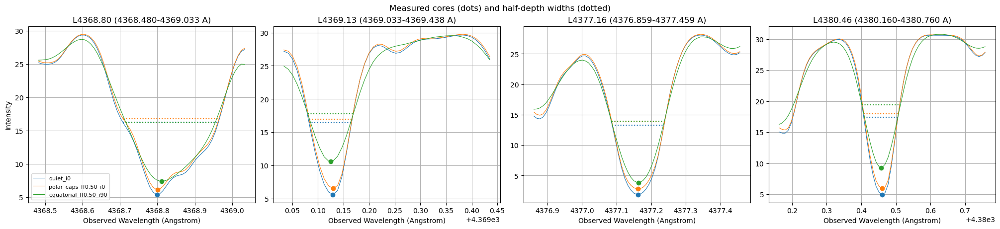

35 features, 210 training and 101 test spectra



===== ff: test accuracy 0.891 =====
  grid, i on dense node (36)   1.000
  grid, i off node (54)        0.889
  random targets (11)          0.545
  within one ff step (0.05): 1.000

  rank feature                                   accuracy drop
     1 equivalent width L4380.46                +0.051 +/- 0.025
     2 half-depth width L4377.16                +0.036 +/- 0.021
     3 continuum W4380                          +0.036 +/- 0.018
     4 equivalent width L4369.13                +0.031 +/- 0.014
     5 continuum W4369                          +0.025 +/- 0.014
     6 EW ratio L4369.13/L4377.16               +0.019 +/- 0.016
     7 equivalent width L4368.80                +0.016 +/- 0.018
     8 bisector span L4377.16                   +0.004 +/- 0.008
     9 bisector span L4368.80                   +0.003 +/- 0.012
    10 continuum ratio W4380/W4377              +0.003 +/- 0.013
    11 core shift L4380.46                      +0.002 +/- 0.013
    12 core shift L4377.16            


===== inclination: test accuracy 0.891 =====
  grid, i on dense node (36)   1.000
  grid, i off node (54)        0.796
  random targets (11)          1.000
  within one i step (15 deg): 1.000

  rank feature                                   accuracy drop
     1 core intensity L4369.13                  +0.004 +/- 0.005
     2 continuum ratio W4369/W4377              +0.000 +/- 0.000
     3 continuum ratio W4380/W4377              +0.000 +/- 0.000
     4 EW ratio L4380.46/L4377.16               +0.000 +/- 0.000
     5 EW ratio L4369.13/L4377.16               +0.000 +/- 0.000
     6 core shift L4380.46                      +0.000 +/- 0.000
     7 EW ratio L4368.80/L4377.16               +0.000 +/- 0.000
     8 equivalent width L4380.46                +0.000 +/- 0.000
     9 bisector span L4377.16                   +0.000 +/- 0.000
    10 core intensity L4380.46                  +0.000 +/- 0.000
    11 bisector span L4380.46                   +0.000 +/- 0.000
    12 half-depth width L437


===== closest model: test accuracy 0.495 =====
  grid, i on dense node (36)   1.000
  grid, i off node (54)        0.185
  random targets (11)          0.364

  rank feature                                   accuracy drop
     1 equivalent width L4377.16                +0.023 +/- 0.010
     2 core shift L4377.16                      +0.018 +/- 0.011
     3 half-depth width L4377.16                +0.018 +/- 0.011
     4 bisector span L4368.80                   +0.017 +/- 0.009
     5 depth ratio L4368.80/L4377.16            +0.016 +/- 0.014
     6 EW ratio L4368.80/L4377.16               +0.015 +/- 0.006
     7 depth L4368.80                           +0.014 +/- 0.010
     8 core shift L4380.46                      +0.014 +/- 0.010
     9 depth ratio L4369.13/L4377.16            +0.013 +/- 0.007
    10 EW ratio L4369.13/L4377.16               +0.012 +/- 0.006
    11 continuum W4369                          +0.011 +/- 0.014
    12 depth L4377.16                           +0.011 +/- 0.0

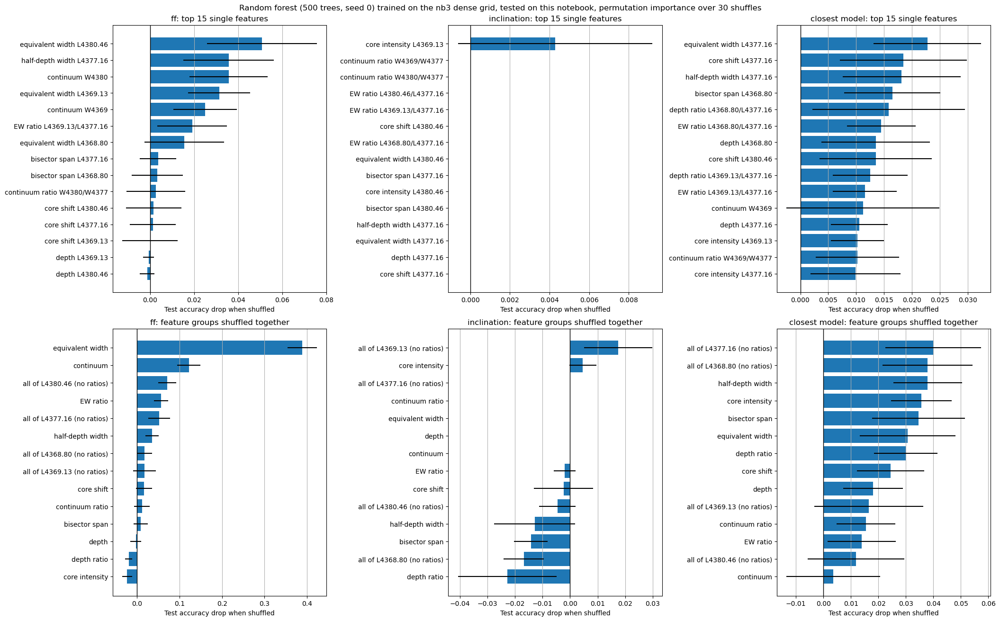

In [5]:
# ===== which line properties carry the facular information: random forest + permutation importance =====
# Features are measured on the four lines inside the three chi^2 windows (4368.80 and 4369.13 A share the
# first window) of the noiseless, unnormalised spectra. Three random forests are trained on the nb3 dense
# grid (210 models: i 0-90 step 15, ff 0.05-0.50 step 0.05, same v_eq, res3d, res2d, SSD/200G and bins as
# here) and tested on this notebook's 101 spectra (90 grid + random faculae + 10 random-band targets):
#   ff             the dense ff nearest the test spectrum's ff (target ff for grid runs, visible ff otherwise)
#   inclination    the dense inclination nearest the test inclination
#   closest model  the dense (geometry, i, ff) model with the lowest line-window chi^2 (free offset, as above)
# Importance = drop in test accuracy when one feature (or a group of features) is shuffled across the test
# spectra. Correlated features share credit (e.g. depth and core intensity of the same line), so a feature
# can rank low on its own while its group ranks high: read the group tables alongside the single ones.
# The 'core intensity' and 'continuum' features are absolute intensities; an observed spectrum only gives
# them after flux calibration, whereas the other features are relative.
import re
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

ml_seed = 0                      # random forests and permutation shuffles
ml_n_trees = 500
ml_n_repeats = 30                # shuffles per feature or group
speed_of_light = 299792458.0     # m/s, exact (SI definition)

# ----- nb3 dense grid: the training set -----
dense_cache_file = './outputs/gridsearch/3_gridsearch_dense_v4000_res3d5_res2d200_4300.1_4399.9_i15_ff005.npz'
dense_cached = np.load(dense_cache_file)
# nb3 saved [v_eq, res3d, res2d, n_wavelengths]; grid_config here starts with the same four.
if not np.array_equal(dense_cached['config'], grid_config[:4]):
    raise ValueError(f"{dense_cache_file} config {dense_cached['config']} differs from this notebook's {grid_config[:4]}")
dense_name_pattern = re.compile(r'^(polar_caps|equatorial|bands_pm30)_ff([0-9.]+)_i([0-9]+)$')
dense_models = []
for name, visible_ff in zip(dense_cached['run_names'], dense_cached['visible_ffs']):
    match = dense_name_pattern.match(str(name))
    if match is None:
        raise ValueError(f"Unexpected dense run name {name}")
    dense_models.append({'name': str(name), 'geometry': match.group(1), 'target_ff': float(match.group(2)),
                         'inc': int(match.group(3)), 'visible_ff': float(visible_ff),
                         'bins': dense_cached[f'bins_{name}'], 'spectrum': dense_cached[f'spectrum_{name}']})
dense_ff_values = np.array(sorted({model['target_ff'] for model in dense_models}))
dense_inc_values = np.array(sorted({model['inc'] for model in dense_models}))
print(f"Training: {len(dense_models)} dense models, ff {list(dense_ff_values)}, i {list(dense_inc_values)} deg")

# Same settings, so the spectra at nodes shared with this grid must agree to summation order.
n_shared = 0
for model in dense_models:
    if model['name'] in grid_spectra:
        bins, spectrum, _ = grid_spectra[model['name']]
        if not (np.array_equal(bins, model['bins']) and np.allclose(spectrum, model['spectrum'], rtol=1e-10, atol=0)):
            raise ValueError(f"Dense {model['name']} differs from this notebook's spectrum")
        n_shared += 1
print(f"{n_shared} dense models are also in this grid and match it (rtol 1e-10)")

# ----- the four lines -----
# Centres are the quiet_i0 minima nearest these guesses. The first window holds a blended pair, split at
# the quiet_i0 maximum between the two cores.
quiet_bins, quiet_spectrum, _ = grid_spectra['quiet_i0']
ml_centre_guesses = [4368.80, 4369.13, 4377.16, 4380.46]   # A
ml_line_centres = []
for guess in ml_centre_guesses:
    near_guess = np.abs(quiet_bins - guess) <= 0.05   # A
    ml_line_centres.append(quiet_bins[near_guess][np.argmin(quiet_spectrum[near_guess])])
between_pair = (quiet_bins > ml_line_centres[0]) & (quiet_bins < ml_line_centres[1])
pair_split = quiet_bins[between_pair][np.argmax(quiet_spectrum[between_pair])]   # A
# (label, quiet_i0 core (A), sub-window lower (A), sub-window upper (A), index of its chi^2 window)
ml_lines = [(f'L{ml_line_centres[0]:.2f}', ml_line_centres[0], line_windows[0][0], pair_split, 0),
            (f'L{ml_line_centres[1]:.2f}', ml_line_centres[1], pair_split, line_windows[0][1], 0),
            (f'L{ml_line_centres[2]:.2f}', ml_line_centres[2], line_windows[1][0], line_windows[1][1], 1),
            (f'L{ml_line_centres[3]:.2f}', ml_line_centres[3], line_windows[2][0], line_windows[2][1], 2)]
ml_window_labels = [f'W{(lower + upper) / 2:.0f}' for lower, upper in line_windows]
for line_label, centre, lower, upper, window in ml_lines:
    print(f"{line_label}: quiet_i0 core {centre:.4f} A, measured in {lower:.3f}-{upper:.3f} A ({ml_window_labels[window]})")


# ----- line measurements -----
def window_slice(bins, spectrum, lower, upper, label):
    """Bins and intensities in [lower, upper] A; every common bin in that range must be present."""
    in_range = (bins >= lower) & (bins <= upper)
    expected = np.sum((common_bins >= lower) & (common_bins <= upper))
    if in_range.sum() != expected:
        raise ValueError(f"{label}: {in_range.sum()} bins in {lower:.3f}-{upper:.3f} A, expected {expected}")
    return bins[in_range], spectrum[in_range]


def level_crossings(wav, flux, k, level):
    """Wavelengths (A) where the profile first rises to `level` either side of minimum bin k (linear interpolation)."""
    left = k
    while flux[left] < level:
        left -= 1
    right = k
    while flux[right] < level:
        right += 1
    wav_left = np.interp(level, [flux[left + 1], flux[left]], [wav[left + 1], wav[left]])
    wav_right = np.interp(level, [flux[right - 1], flux[right]], [wav[right - 1], wav[right]])
    return wav_left, wav_right


def measure_line(wav, flux, continuum, centre, label):
    """(features, diagnostics) of one absorption line; continuum is its window's pseudo-continuum (max intensity)."""
    k = int(np.argmin(flux))
    if k == 0 or k == len(flux) - 1:
        raise ValueError(f"{label}: minimum at the sub-window edge, so the line is not resolved inside it")
    # Parabola through the minimum bin and its neighbours gives a sub-bin core, needed because the
    # rotational shifts of interest (~100 m/s) are a fraction of one 0.0087 A (~600 m/s) bin.
    flux_left, flux_mid, flux_right = flux[k - 1], flux[k], flux[k + 1]
    vertex = 0.5 * (flux_left - flux_right) / (flux_left - 2 * flux_mid + flux_right)   # bins from k
    core_wav = wav[k] + vertex * (wav[k + 1] - wav[k - 1]) / 2   # A
    core_flux = flux_mid - 0.25 * (flux_left - flux_right) * vertex
    # Top of the line = the lower of its two shoulders, so every level below it is crossed on both sides
    # (the blended pair has no true continuum between its cores).
    top = min(flux[:k].max(), flux[k + 1:].max())
    crossings = {}
    for fraction in (0.25, 0.5, 0.75):   # fraction of the way from the core up to the top
        level = core_flux + fraction * (top - core_flux)
        if level <= flux_mid:
            raise ValueError(f"{label}: level at fraction {fraction} is below the minimum bin")
        crossings[fraction] = level_crossings(wav, flux, k, level)
    bisector = {fraction: (left + right) / 2 for fraction, (left, right) in crossings.items()}   # A
    bin_widths = np.gradient(wav)   # A, the bins are log-uniform
    features = {
        'core intensity': core_flux,
        'depth': 1 - core_flux / continuum,
        'half-depth width': (crossings[0.5][1] - crossings[0.5][0]) / centre * speed_of_light,   # m/s
        'equivalent width': np.sum((1 - flux / continuum) * bin_widths) * 1e3,   # mA, against the window pseudo-continuum
        'core shift': (core_wav - centre) / centre * speed_of_light,   # m/s, relative to the quiet_i0 core
        'bisector span': (bisector[0.75] - bisector[0.25]) / centre * speed_of_light,   # m/s, upper minus lower
    }
    diagnostics = {'core_wav': core_wav, 'core_flux': core_flux, 'half_crossings': crossings[0.5],
                   'half_level': core_flux + 0.5 * (top - core_flux)}
    return features, diagnostics


def spectrum_features(bins, spectrum, label):
    """Ordered dict of every feature of one spectrum."""
    features = {}
    window_continua = []
    for window_label, (lower, upper) in zip(ml_window_labels, line_windows):
        _, window_flux = window_slice(bins, spectrum, lower, upper, label)
        window_continua.append(window_flux.max())
        features[f'continuum {window_label}'] = window_flux.max()
    for line_label, centre, lower, upper, window in ml_lines:
        wav, flux = window_slice(bins, spectrum, lower, upper, f'{label} {line_label}')
        line_features, _ = measure_line(wav, flux, window_continua[window], centre, f'{label} {line_label}')
        for quantity, value in line_features.items():
            features[f'{quantity} {line_label}'] = value
    # Relative line heights and strengths, against the deepest line (4377.16 A)
    reference_label = ml_lines[2][0]
    for line_label, *_ in ml_lines:
        if line_label == reference_label:
            continue
        features[f'depth ratio {line_label}/{reference_label}'] = features[f'depth {line_label}'] / features[f'depth {reference_label}']
        features[f'EW ratio {line_label}/{reference_label}'] = (features[f'equivalent width {line_label}']
                                                                / features[f'equivalent width {reference_label}'])
    features[f'continuum ratio {ml_window_labels[0]}/{ml_window_labels[1]}'] = window_continua[0] / window_continua[1]
    features[f'continuum ratio {ml_window_labels[2]}/{ml_window_labels[1]}'] = window_continua[2] / window_continua[1]
    return features


# ----- measurement check: profiles with the measured core and half-depth width -----
check_names = ['quiet_i0', 'polar_caps_ff0.50_i0', 'equatorial_ff0.50_i90']
fig, axes = plt.subplots(1, len(ml_lines), figsize=(5 * len(ml_lines), 4.5), constrained_layout=True)
for ax, (line_label, centre, lower, upper, window) in zip(axes, ml_lines):
    for name in check_names:
        bins, spectrum, _ = grid_spectra[name]
        _, window_flux = window_slice(bins, spectrum, *line_windows[window], name)
        wav, flux = window_slice(bins, spectrum, lower, upper, name)
        _, diagnostics = measure_line(wav, flux, window_flux.max(), centre, f'{name} {line_label}')
        lines = ax.plot(wav, flux, linewidth=0.8, label=name)
        ax.plot(diagnostics['core_wav'], diagnostics['core_flux'], marker='o', color=lines[0].get_color())
        ax.hlines(diagnostics['half_level'], *diagnostics['half_crossings'], color=lines[0].get_color(), linestyle=':')
    ax.set_title(f'{line_label} ({lower:.3f}-{upper:.3f} A)')
    ax.set_xlabel('Observed Wavelength (Angstrom)')
    ax.grid(True)
axes[0].set_ylabel('Intensity')
axes[0].legend(fontsize=8)
fig.suptitle('Measured cores (dots) and half-depth widths (dotted)')
plt.show()

# ----- feature matrices -----
dense_rows = [spectrum_features(model['bins'], model['spectrum'], model['name']) for model in dense_models]
feature_names = list(dense_rows[0])
X_train = np.array([[row[feature] for feature in feature_names] for row in dense_rows])

test_runs = [run for run in grid_runs if run['kind'] == 'grid'] + [runs_by_name['random']] + band_targets
test_spectra = []
for run in test_runs:
    bins, spectrum, _ = band_spectra[run['name']] if run['kind'] == 'random_bands' else grid_spectra[run['name']]
    test_spectra.append((bins, spectrum))
test_rows = [spectrum_features(bins, spectrum, run['name']) for run, (bins, spectrum) in zip(test_runs, test_spectra)]
X_test = np.array([[row[feature] for feature in feature_names] for row in test_rows])
for label, X in (('training', X_train), ('test', X_test)):
    if not np.all(np.isfinite(X)):
        raise ValueError(f"Non-finite {label} features: {[feature_names[c] for c in np.where(~np.all(np.isfinite(X), axis=0))[0]]}")
print(f"{len(feature_names)} features, {len(X_train)} training and {len(X_test)} test spectra")


# ----- labels -----
def nearest_value(value, options, label):
    distances = np.abs(options - value)
    order = np.argsort(distances)
    if np.isclose(distances[order[0]], distances[order[1]]):
        raise ValueError(f"{label}: {value} is equidistant from {options[order[0]]} and {options[order[1]]}")
    return options[order[0]]


line_bin_values = common_bins[in_line_windows]


def on_line_bins(bins, spectrum, label):
    on_lines = np.isin(bins, line_bin_values)
    if on_lines.sum() != len(line_bin_values):
        raise ValueError(f"{label} does not cover all {len(line_bin_values)} line-window bins")
    return spectrum[on_lines]


dense_line_spectra = [on_line_bins(model['bins'], model['spectrum'], model['name']) for model in dense_models]


def closest_dense_model(line_spectrum):
    """Dense model with the lowest line-window chi^2, free additive offset (the statistic of this notebook)."""
    chi2_values = []
    for model_spectrum in dense_line_spectra:
        offset = np.mean(line_spectrum - model_spectrum)
        chi2_values.append(np.sum((line_spectrum - (model_spectrum + offset)) ** 2))
    return dense_models[int(np.argmin(chi2_values))]['name']


ff_step = dense_ff_values[1] - dense_ff_values[0]
y_train = {'ff': [f"{model['target_ff']:.2f}" for model in dense_models],
           'inclination': [str(model['inc']) for model in dense_models],
           'closest model': [model['name'] for model in dense_models]}
y_test = {'ff': [], 'inclination': [], 'closest model': []}
for run, (bins, spectrum) in zip(test_runs, test_spectra):
    ff_true = run['target_ff'] if run['kind'] == 'grid' else run['visible_ff']
    if not dense_ff_values[0] - ff_step / 2 <= ff_true <= dense_ff_values[-1] + ff_step / 2:
        print(f"WARNING: {run['name']} ff {ff_true:.4f} is outside the dense ff range; labelled with the nearest end")
    y_test['ff'].append(f"{nearest_value(ff_true, dense_ff_values, run['name']):.2f}")
    y_test['inclination'].append(str(nearest_value(run['inc'], dense_inc_values, run['name'])))
    y_test['closest model'].append(closest_dense_model(on_line_bins(bins, spectrum, run['name'])))
y_train = {task: np.array(labels) for task, labels in y_train.items()}
y_test = {task: np.array(labels) for task, labels in y_test.items()}

# Accuracy by subset: grid runs on a dense inclination node are exact copies of training spectra.
on_node = np.array([run['kind'] == 'grid' and run['inc'] in dense_inc_values for run in test_runs])
off_node = np.array([run['kind'] == 'grid' and run['inc'] not in dense_inc_values for run in test_runs])
is_target = np.array([run['kind'] != 'grid' for run in test_runs])
test_subsets = {f'grid, i on dense node ({on_node.sum()})': on_node,
                f'grid, i off node ({off_node.sum()})': off_node,
                f'random targets ({is_target.sum()})': is_target}


# ----- groups: one per quantity (all lines together), and one per line (its six own features) -----
feature_groups = {}
for column, feature in enumerate(feature_names):
    quantity = feature.rsplit(' ', 1)[0]   # 'depth L4377.16' -> 'depth', 'depth ratio L4368.80/L4377.16' -> 'depth ratio'
    feature_groups.setdefault(quantity, []).append(column)
for line_label, *_ in ml_lines:
    feature_groups[f'all of {line_label} (no ratios)'] = [column for column, feature in enumerate(feature_names)
                                                         if feature.endswith(f' {line_label}')]


def group_importance(forest, X, y, columns, rng):
    """Mean and std of the accuracy drop when the columns are shuffled together (same row order)."""
    baseline = np.mean(forest.predict(X) == y)
    drops = []
    for _ in range(ml_n_repeats):
        X_shuffled = X.copy()
        X_shuffled[:, columns] = X[rng.permutation(len(X))][:, columns]
        drops.append(baseline - np.mean(forest.predict(X_shuffled) == y))
    return np.mean(drops), np.std(drops)


# ----- train, test, rank -----
ml_results = {}
for task in ['ff', 'inclination', 'closest model']:
    forest = RandomForestClassifier(n_estimators=ml_n_trees, random_state=ml_seed, n_jobs=grid_n_workers)
    forest.fit(X_train, y_train[task])
    predicted = forest.predict(X_test)
    correct = predicted == y_test[task]
    single = permutation_importance(forest, X_test, y_test[task], scoring='accuracy', n_repeats=ml_n_repeats,
                                    random_state=ml_seed)
    rng = np.random.default_rng(ml_seed)
    groups = {group: group_importance(forest, X_test, y_test[task], columns, rng) for group, columns in feature_groups.items()}
    ml_results[task] = {'predicted': predicted, 'single': single, 'groups': groups}

    print(f"\n===== {task}: test accuracy {correct.mean():.3f} =====")
    for subset, mask in test_subsets.items():
        print(f"  {subset:28s} {correct[mask].mean():.3f}")
    if task == 'ff':
        within_one = np.abs(predicted.astype(float) - y_test[task].astype(float)) <= ff_step * 1.001
        print(f"  within one ff step ({ff_step:.2f}): {within_one.mean():.3f}")
    if task == 'inclination':
        within_one = np.abs(predicted.astype(float) - y_test[task].astype(float)) <= 15
        print(f"  within one i step (15 deg): {within_one.mean():.3f}")
    print(f"\n  {'rank':>4s} {'feature':40s} {'accuracy drop':>14s}")
    for rank, column in enumerate(np.argsort(single.importances_mean)[::-1], start=1):
        print(f"  {rank:4d} {feature_names[column]:40s} {single.importances_mean[column]:+.3f} +/- {single.importances_std[column]:.3f}")
    print(f"\n  {'rank':>4s} {'group (features shuffled together)':40s} {'accuracy drop':>14s}")
    for rank, group in enumerate(sorted(groups, key=lambda group: groups[group][0], reverse=True), start=1):
        print(f"  {rank:4d} {group:40s} {groups[group][0]:+.3f} +/- {groups[group][1]:.3f}")

# ----- the 11 targets -----
print(f"\n{'target':22s} {'i':>6s} {'ff':>6s} | {'true ff':>7s} {'pred':>5s} | {'true i':>6s} {'pred':>4s} | "
      f"{'line chi^2 closest (dense)':28s} {'RF prediction':28s}")
for t in np.where(is_target)[0]:
    run = test_runs[t]
    print(f"{run['name']:22s} {run['inc']:6.1f} {run['visible_ff']:6.3f} | {y_test['ff'][t]:>7s} {ml_results['ff']['predicted'][t]:>5s} | "
          f"{y_test['inclination'][t]:>6s} {ml_results['inclination']['predicted'][t]:>4s} | "
          f"{y_test['closest model'][t]:28s} {ml_results['closest model']['predicted'][t]:28s}")

# ----- importance plots -----
n_top = 15
fig, axes = plt.subplots(2, 3, figsize=(21, 13), constrained_layout=True)
for column, task in enumerate(ml_results):
    single = ml_results[task]['single']
    top = np.argsort(single.importances_mean)[::-1][:n_top][::-1]   # largest at the top of the plot
    axes[0, column].barh([feature_names[c] for c in top], single.importances_mean[top], xerr=single.importances_std[top])
    axes[0, column].set_title(f'{task}: top {n_top} single features')
    groups = ml_results[task]['groups']
    group_order = sorted(groups, key=lambda group: groups[group][0])
    axes[1, column].barh(group_order, [groups[group][0] for group in group_order], xerr=[groups[group][1] for group in group_order])
    axes[1, column].set_title(f'{task}: feature groups shuffled together')
    for ax in axes[:, column]:
        ax.axvline(0, color='k', linewidth=1)
        ax.set_xlabel('Test accuracy drop when shuffled')
        ax.grid(True, axis='x')
fig.suptitle(f'Random forest ({ml_n_trees} trees, seed {ml_seed}) trained on the nb3 dense grid, tested on this notebook, '
             f'permutation importance over {ml_n_repeats} shuffles')
plt.show()
